
=== LP OPTIMAL MAKESPAN = 5.0 ===

=== LP STEP ===
Time step: 0
Machines: 2/2 free

DAG 0:
  Inactive : ['C', 'B', 'A']
  Active   : []
  Completed: []

DAG 1:
  Inactive : ['Y', 'X']
  Active   : []
  Completed: []

Available jobs: ['A', 'X']


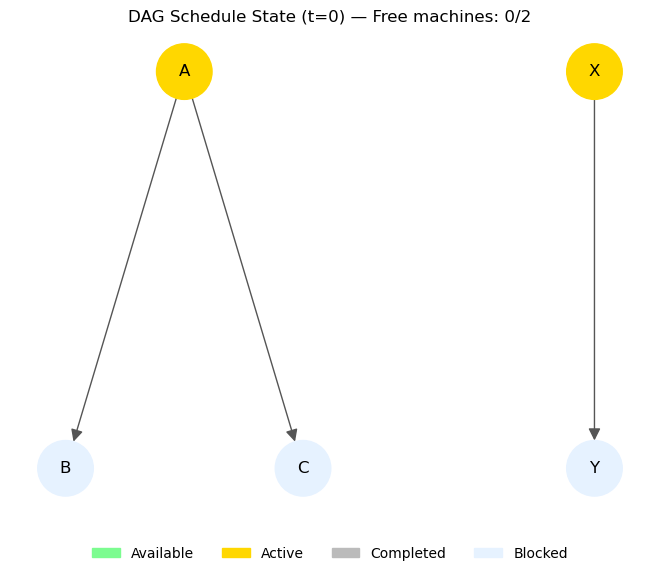


=== LP STEP ===
Time step: 1
Machines: 2/2 free

DAG 0:
  Inactive : ['C', 'B']
  Active   : []
  Completed: ['A']

DAG 1:
  Inactive : ['Y']
  Active   : []
  Completed: ['X']

Available jobs: ['C', 'B', 'Y']


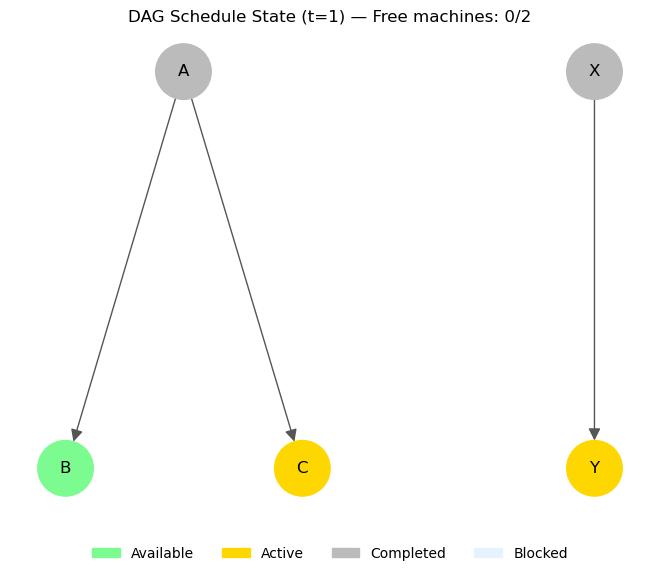


=== LP STEP ===
Time step: 2
Machines: 0/2 free

DAG 0:
  Inactive : ['B']
  Active   : ['C']
  Completed: ['A']

DAG 1:
  Inactive : []
  Active   : ['Y']
  Completed: ['X']

Available jobs: ['B']


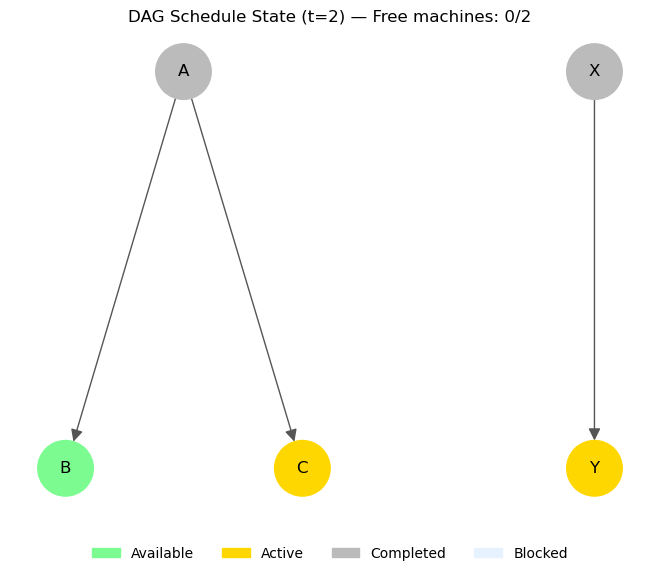


=== LP STEP ===
Time step: 3
Machines: 2/2 free

DAG 0:
  Inactive : ['B']
  Active   : []
  Completed: ['C', 'A']

DAG 1:
  Inactive : []
  Active   : []
  Completed: ['Y', 'X']

Available jobs: ['B']


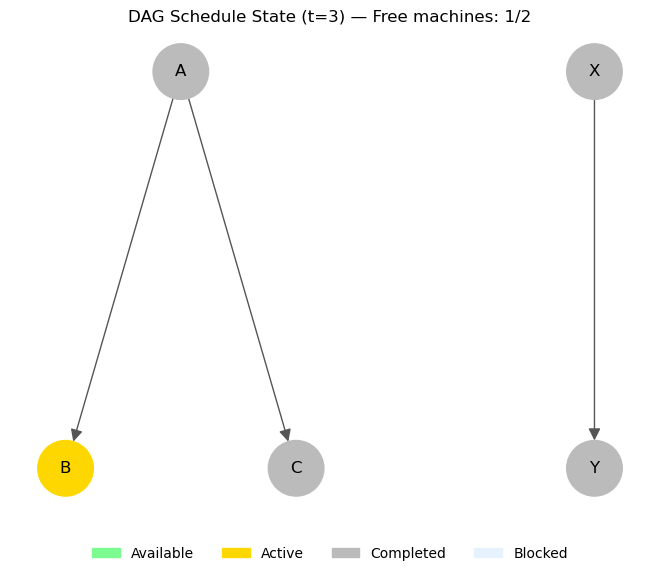


=== LP STEP ===
Time step: 4
Machines: 1/2 free

DAG 0:
  Inactive : []
  Active   : ['B']
  Completed: ['C', 'A']

DAG 1:
  Inactive : []
  Active   : []
  Completed: ['Y', 'X']

Available jobs: []


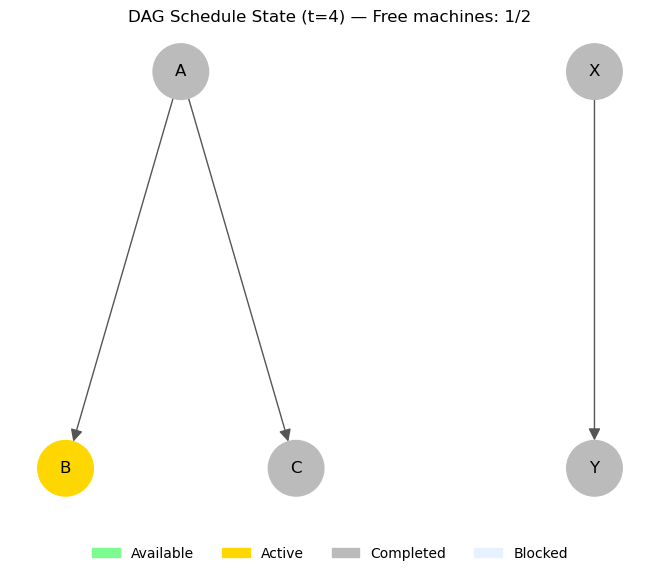


=== ALL JOBS COMPLETED (LP SCHEDULE) ===


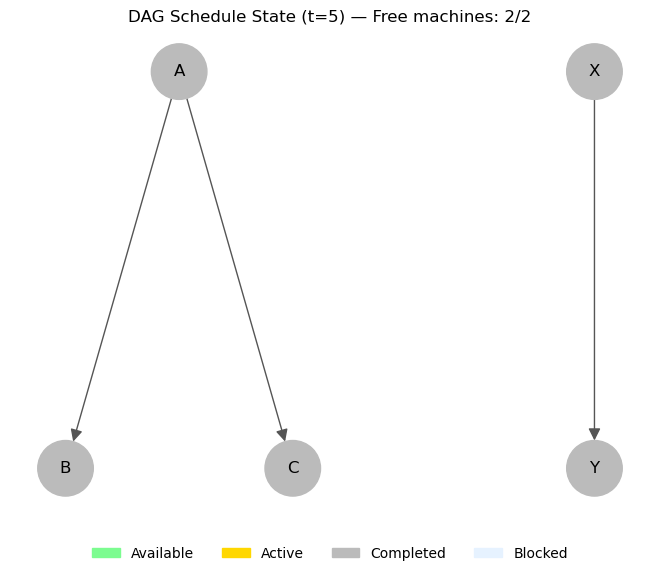

In [ ]:
from job import Job
from dag import DAG
from dag_schedule import DAGSchedule
import pulp

def dump_schedule_state(sched, header=None):
    if header:
        print(f"\n=== {header} ===")

    print(f"Time step: {sched.time_step}")
    print(f"Machines: {sched.free_machines}/{sched.num_machines} free")

    for i, dag in enumerate(sched.dags):
        print(f"\nDAG {i}:")
        print("  Inactive :", [j.name for j in sched.inactive[dag]])
        print("  Active   :", [j.name for j in sched.active[dag]])
        print("  Completed:", [j.name for j in sched.completed[dag]])

    avail = [job.name for _, job in sched.available()]
    print("\nAvailable jobs:", avail)


def greedy_schedule(sched):
    """
    Time-driven greedy scheduler.
    Always advances time.
    Never raises deadlock.
    """
    total_jobs = sum(len(dag.nodes()) for dag in sched.dags)

    while True:
        completed_jobs = sum(len(sched.completed[dag]) for dag in sched.dags)
        if completed_jobs == total_jobs:
            print("\n=== ALL JOBS COMPLETED ===")
            sched.draw()
            break

        dump_schedule_state(sched, "GREEDY STEP")

        # Try to start jobs
        for dag, job in list(sched.available()):
            if sched.free_machines <= 0:
                break
            sched.consume(dag, job)

        sched.draw()

        # ALWAYS advance time
        sched.step()

def lp_schedule(sched):
    """
    Offline LP-based scheduler (clairvoyant oracle).
    Solves a time-indexed ILP with PuLP, then replays the solution
    using the existing DAGSchedule mechanics.
    """

    # ---------------- Collect jobs and edges ----------------

    jobs = []
    edges = []

    for dag in sched.dags:
        for job in dag.nodes():
            jobs.append(job)
        for u, v in dag.edges():
            edges.append((u, v))

    # ---------------- Time horizon ----------------

    T = sum(job.time_estimate for job in jobs)

    # ---------------- Build ILP ----------------

    model = pulp.LpProblem("DAG_Scheduling", pulp.LpMinimize)

    x = {
        (job, t): pulp.LpVariable(f"x_{job.name}_{t}", cat="Binary")
        for job in jobs
        for t in range(T - job.time_estimate + 1)
    }

    C_max = pulp.LpVariable("C_max", lowBound=0)
    model += C_max

    # Each job starts exactly once
    for job in jobs:
        model += (
            pulp.lpSum(
                x[job, t] for t in range(T - job.time_estimate + 1)
            ) == 1
        )

    # Precedence constraints
    for i, j in edges:
        model += (
            pulp.lpSum(
                t * x[j, t] for t in range(T - j.time_estimate + 1)
            )
            >=
            pulp.lpSum(
                (t + i.time_estimate) * x[i, t]
                for t in range(T - i.time_estimate + 1)
            )
        )

    # Machine capacity
    for t in range(T):
        model += (
            pulp.lpSum(
                x[job, tau]
                for job in jobs
                for tau in range(
                    max(0, t - job.time_estimate + 1),
                    min(t, T - job.time_estimate) + 1,
                )
            )
            <= sched.num_machines
        )

    # Makespan definition
    for job in jobs:
        model += (
            C_max
            >=
            pulp.lpSum(
                (t + job.time_estimate) * x[job, t]
                for t in range(T - job.time_estimate + 1)
            )
        )

    # ---------------- Solve ----------------

    model.solve(pulp.PULP_CBC_CMD(msg=False))

    if pulp.LpStatus[model.status] != "Optimal":
        raise RuntimeError("LP did not find an optimal solution")

    print(f"\n=== LP OPTIMAL MAKESPAN = {pulp.value(C_max)} ===")

    # ---------------- Extract start times ----------------

    start_time = {}

    for (job, t), var in x.items():
        if pulp.value(var) == 1:
            start_time[job] = t

    # ---------------- Replay schedule ----------------

    total_jobs = len(jobs)

    while True:
        completed_jobs = sum(len(sched.completed[dag]) for dag in sched.dags)
        if completed_jobs == total_jobs:
            print("\n=== ALL JOBS COMPLETED (LP SCHEDULE) ===")
            sched.draw()
            break

        dump_schedule_state(sched, "LP STEP")

        # Start jobs whose LP start time is now
        for dag in sched.dags:
            for job in list(sched.inactive[dag]):
                if start_time.get(job) == sched.time_step:
                    sched.consume(dag, job)

        sched.draw()
        sched.step()

# ---------------- Define DAG jobs ----------------

A = Job("A", time_estimate=1)
B = Job("B", time_estimate=3)
C = Job("C", time_estimate=1)

X = Job("X", time_estimate=2)
Y = Job("Y", time_estimate=2)
Z = Job("Z", time_estimate=3)

dag1 = DAG()
dag1.add_edge(A, B)
dag1.add_edge(B, C)   # chain with a long middle

dag2 = DAG()
dag2.add_edge(X, Y)
dag2.add_edge(X, Z)   # fork into two long-ish jobs


# ---------------- Initialize schedule (TWO MACHINES) ----------------
sched = DAGSchedule([dag1, dag2], num_machines=2)
#greedy_schedule(sched)
lp_schedule(sched)